# DSA4060XA – Week 6 Guided Practical Lab

## Evaluating Recommender Systems

**Student ID:** 671243  
**Course:** DSA4060XA – Recommender Systems

### Lab Objective

The objective of this practical is to develop and evaluate three movie recommendation approaches: a popularity baseline, content-based filtering, and item-based collaborative filtering.

The models will be evaluated using rating prediction metrics (MAE and RMSE), Top-N ranking metrics (Precision@K, Recall@K, and NDCG@K), and beyond-accuracy metrics (catalogue coverage, novelty, and diversity).

The evaluation will help determine which recommendation approach is most appropriate for a streaming service that wants to provide relevant movie suggestions while encouraging users to discover a wider variety of content.

### Step 1: Import Required Libraries

The first step is to import the Python libraries required for data processing, recommendation modelling, evaluation, and visualization.

- **pandas:** Used to load, inspect, and manipulate the movie and ratings datasets.
- **NumPy:** Supports numerical calculations and mathematical operations.
- **Matplotlib:** Used to visualize rating distributions and model performance.
- **scikit-learn:** Provides functions for calculating prediction errors and cosine similarity between movies and user preferences.

A constant `TOP_K = 3` is defined because the lab evaluates recommendation lists containing three movies.

In [1]:
# Import libraries for data manipulation
import pandas as pd
import numpy as np

# Import library for data visualization
import matplotlib.pyplot as plt

# Import evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Import cosine similarity for recommendation models
from sklearn.metrics.pairwise import cosine_similarity

# Number of movies to recommend
TOP_K = 3

print("All libraries imported successfully.")

All libraries imported successfully.


### Step 2: Load and Inspect the Datasets

This step involves loading the two CSV files provided for the practical and examining their structure.

The datasets are:

1. **DSA4060_Week6_Movies.csv:** Contains movie information, including movie identifiers, titles, and genres.
2. **DSA4060_Week6_Ratings.csv:** Contains user–movie interactions, including user identifiers, movie identifiers, ratings, and timestamps.

The datasets are loaded using the `pd.read_csv()` function. The `head()` method displays the first five records, allowing us to verify that the files have been loaded correctly.

We also calculate the number of unique users, unique rated movies, and total rating interactions. Understanding these characteristics is important before building recommendation models because the models depend on user preferences, item information, and historical interactions.

In [2]:
# Load the datasets
movies = pd.read_csv("DSA4060_Week6_Movies.csv")
ratings = pd.read_csv("DSA4060_Week6_Ratings.csv")

# Display the first five rows of each dataset
print("Movies Dataset:")
display(movies.head())

print("Ratings Dataset:")
display(ratings.head())

# Calculate dataset statistics
print("Number of unique users:", ratings["user_id"].nunique())
print("Number of unique rated movies:", ratings["movie_id"].nunique())
print("Total number of ratings:", len(ratings))

Movies Dataset:


,movie_id,title,genres
0,1,Galaxy Mission,Action|Sci-Fi
1,2,Love in Nairobi,Romance|Drama
2,3,Final Battle,Action
3,4,Family Weekend,Comedy|Family
4,5,Future World,Sci-Fi|Action


Ratings Dataset:


,user_id,movie_id,rating,timestamp
0,1,2,3,1
1,1,10,3,2
2,1,1,5,3
3,1,9,3,4
4,1,7,3,5


Number of unique users: 12
Number of unique rated movies: 20
Total number of ratings: 120


### Step 2: Student Check and Interpretation

**1. What does one row in the movies dataset represent?**

Each row represents a movie with a unique identifier, title, and associated genres. For example, Galaxy Mission (Movie ID 1) belongs to the Action and Sci-Fi genres.

**2. What does one row in the ratings dataset represent?**

Each row represents a rating given by a particular user to a movie at a recorded timestamp. For example, User 1 rated Galaxy Mission 5 out of 5 at timestamp 3.

**3. How many unique users and movies are present?**

The ratings dataset contains 12 unique users, 20 unique rated movies, and 120 rating interactions.

**4. What type of feedback is represented by the rating column?**

The ratings represent explicit feedback because users directly express their preferences by assigning numerical scores to movies.

**5. What is the rating scale?**

The rating scale ranges from 1 to 5, with higher scores indicating stronger preferences.

### Interpretation

- The dataset contains 120 ratings from 12 users across 20 movies. 
- This gives an average of 10 ratings per user. 
- There are 240 possible user–movie combinations, meaning that 50% of the possible interactions have been observed.

- The movie genres provide the information needed for content-based filtering, while the ratings allow us to develop the popularity baseline and item-based collaborative filtering models.

### Step 3: Inspect Rating Behaviour

Before developing the recommendation models, it is important to examine the distribution of user ratings.

The rating distribution helps identify whether users generally give positive, negative, or moderate feedback. If most ratings are high, a model that frequently predicts high scores may appear accurate without learning meaningful user preferences.

We use the `value_counts()` function to calculate how frequently each rating occurs and a bar chart to visualize the results.

Rating Distribution:


rating
2    29
3    49
4    28
5    14
Name: count, dtype: int64

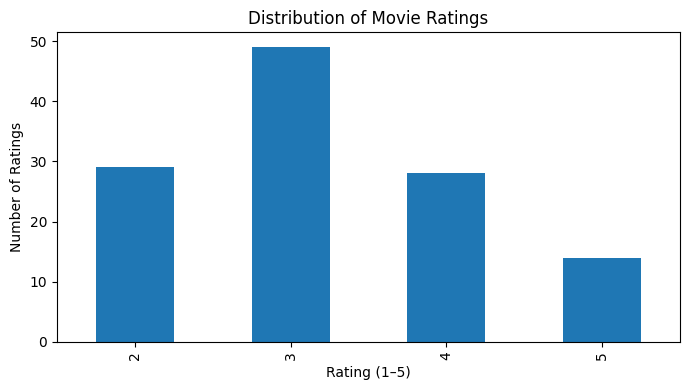

In [3]:
# Count the frequency of each rating
rating_counts = ratings["rating"].value_counts().sort_index()

# Display the rating frequencies
print("Rating Distribution:")
display(rating_counts)

# Create a bar chart
plt.figure(figsize=(7, 4))

rating_counts.plot(kind="bar")

plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating (1–5)")
plt.ylabel("Number of Ratings")

plt.tight_layout()
plt.show()

### Step 3: Interpretation of Rating Behaviour

- The rating distribution shows that moderate ratings dominate the dataset, with rating 3 occurring 49 times (40.8%), followed by rating 2 with 29 occurrences (24.2%) and rating 4 with 28 occurrences (23.3%). Rating 5 is the least frequent, appearing only 14 times (11.7%), while no movies received a rating of 1.

- This indicates that users generally provide moderate feedback rather than extremely positive ratings.
-  The uneven distribution may influence model evaluation because models predicting ratings close to the middle of the scale could achieve relatively low prediction errors without accurately capturing individual user preferences.

### Step 4: Create a Train/Test Split

- To evaluate the recommendation models fairly, the ratings dataset is divided into training and testing sets using a chronological leave-one-out approach.

- The ratings are first sorted by user ID and timestamp. For each user, the most recent interaction is selected as the test observation, while all earlier interactions are retained for training.

- This approach ensures that every user has a training history and one unseen interaction for evaluation. It also reduces the risk of information leakage from future interactions into the training process.

- The same training and testing sets will be used to evaluate all three recommendation models, ensuring a consistent comparison.

In [4]:
# Sort interactions by user and timestamp
ratings = ratings.sort_values(["user_id", "timestamp"])

# Select the most recent rating from each user for testing
test = ratings.groupby("user_id").tail(1).copy()

# Use the remaining ratings for training
train = ratings.drop(test.index).copy()

# Display the number of interactions in each set
print("Training interactions:", len(train))
print("Test interactions:", len(test))

# Display the first five test observations
display(test.head())

Training interactions: 108
Test interactions: 12


,user_id,movie_id,rating,timestamp
9,1,14,4,10
19,2,9,4,20
29,3,18,3,30
39,4,18,3,40
49,5,11,2,50


### Step 4: Interpretation of Train/Test Split

- The chronological leave-one-out splitting approach produced 108 training interactions (90%) and 12 testing interactions (10%) from the original 120 ratings.

- Each of the 12 users contributed their most recent interaction to the test set. For example, User 1's rating of 4 for Movie 14 at timestamp 10 was held out, while User 2's rating of 4 for Movie 9 at timestamp 20 was reserved for testing.

- This approach allows the recommendation models to learn from historical interactions and be evaluated on unseen ratings.
- Using the same split for all three models also ensures a fair comparison of their performance.

### Step 5: Build a Popularity Baseline

The popularity baseline serves as a reference model for evaluating whether more advanced recommendation approaches provide meaningful improvements.

This model uses the average ratings of movies in the training dataset to estimate how users might rate them. It does not account for individual user preferences.

The implementation involves three main operations:

1. Calculating the global mean rating across all training interactions.
2. Computing the mean rating and number of ratings received by each movie.
3. Predicting the ratings of held-out test movies using their training averages, with the global mean used when a movie has no training ratings.

For recommendation ranking, movies are ordered by their average rating, with rating count used to break ties.

Importantly, all statistics are calculated using training data only, preventing information from the test set from influencing the predictions.

In [5]:
# Calculate the global average rating from training data
global_mean = train["rating"].mean()

print("Global Mean Rating:", round(global_mean, 3))

# Calculate average rating and rating count for each movie
movie_stats = (
    train.groupby("movie_id")
    .agg(
        mean_rating=("rating", "mean"),
        rating_count=("rating", "size")
    )
    .reset_index()
    .merge(movies[["movie_id", "title"]], on="movie_id")
)

# Display the top 10 movies ranked by average rating
print("Top 10 Movies by Average Rating:")

display(
    movie_stats.sort_values(
        ["mean_rating", "rating_count"],
        ascending=[False, False]
    ).head(10)
)

# Create a dictionary mapping movie IDs to mean ratings
movie_mean_map = (
    train.groupby("movie_id")["rating"]
    .mean()
    .to_dict()
)

# Create a copy of the test data
baseline_test = test.copy()

# Predict test ratings using each movie's training mean
baseline_test["prediction"] = (
    baseline_test["movie_id"].map(movie_mean_map)
)

# Replace missing predictions with the global mean
baseline_test["prediction"] = (
    baseline_test["prediction"].fillna(global_mean)
)

# Display actual and predicted ratings
print("Baseline Predictions:")
display(
    baseline_test[
        ["user_id", "movie_id", "rating", "prediction"]
    ].head()
)

Global Mean Rating: 3.222
Top 10 Movies by Average Rating:


,movie_id,mean_rating,rating_count,title
5,6,4.166667,6,Broken Hearts
0,1,4.000000,3,Galaxy Mission
17,18,4.000000,2,The Promise
3,4,3.800000,5,Family Weekend
9,10,3.666667,6,Hidden Truth
15,16,3.571429,7,Campus Life
6,7,3.500000,8,City Detectives
12,13,3.400000,5,Digital Dreams
18,19,3.250000,4,Night Chase
2,3,3.166667,6,Final Battle


Baseline Predictions:


,user_id,movie_id,rating,prediction
9,1,14,4,2.857143
19,2,9,4,3.000000
29,3,18,3,4.000000
39,4,18,3,4.000000
49,5,11,2,2.500000


### Step 5: Interpretation of Popularity Baseline Results

- The global mean rating calculated from the 108 training interactions is **3.222**, indicating that users generally provide moderate ratings.

- Broken Hearts achieved the highest average rating of 4.167 from six training interactions, followed by Galaxy Mission with an average of 4.000 from three interactions and The Promise with an average of 4.000 from two interactions. 
- Although Galaxy Mission and The Promise have identical average ratings, Galaxy Mission ranks higher because it received more ratings.

- The baseline predictions also reveal differences between actual and predicted user ratings. For example, User 1 rated Movie 14 a 4, but the model predicted approximately 2.857. Similarly, Users 3 and 4 rated Movie 18 a 3, while the model predicted 4.000 for both.

- These differences highlight a limitation of the popularity baseline: it assigns the same predicted rating to a movie regardless of the user's individual preferences.
- Although the approach is simple and interpretable, it may fail to capture personalized viewing interests.

The next step evaluates the size of these prediction errors using MAE and RMSE.

### Step 6: Evaluate the Popularity Baseline Using MAE and RMSE

After generating rating predictions using the popularity baseline, the next step is to measure their accuracy against the actual ratings in the test dataset.

Two evaluation metrics are used:

**Mean Absolute Error (MAE):** Measures the average absolute difference between predicted and actual ratings. It provides an interpretable measure of how far predictions deviate from observed user ratings.

**Root Mean Squared Error (RMSE):** Measures the square root of the average squared prediction errors. Unlike MAE, RMSE penalizes larger errors more heavily, making it useful for identifying models that produce substantial prediction mistakes.

For both metrics, lower values indicate better predictive performance.

The evaluation uses the 12 held-out test interactions, ensuring that the baseline is assessed on ratings that were not used to calculate its training averages.

These results will serve as reference values when evaluating the content-based and item-based collaborative-filtering models.

In [6]:
# Define a reusable function for rating prediction metrics
def rating_metrics(actual, predicted):

    # Calculate Mean Absolute Error
    mae = mean_absolute_error(actual, predicted)

    # Calculate Root Mean Squared Error
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    return mae, rmse


# Evaluate popularity baseline predictions
baseline_mae, baseline_rmse = rating_metrics(
    baseline_test["rating"],
    baseline_test["prediction"]
)

# Display evaluation results
print("Popularity Baseline Evaluation")
print("------------------------------")
print("Baseline MAE:", round(baseline_mae, 3))
print("Baseline RMSE:", round(baseline_rmse, 3))

Popularity Baseline Evaluation
------------------------------
Baseline MAE: 1.086
Baseline RMSE: 1.201


### Step 6: Interpretation of Popularity Baseline Evaluation

- The popularity baseline achieved a Mean Absolute Error (MAE) of **1.086** and a Root Mean Squared Error (RMSE) of **1.201** on the 12 held-out test interactions.

- The MAE indicates that the model's predicted ratings differ from the actual user ratings by approximately 1.086 points on average. 
- The higher RMSE suggests that some predictions have relatively large errors, which receive greater penalties when squared.

- These results establish a reference point for evaluating the content-based and item-based collaborative-filtering models. Since the popularity baseline does not consider individual user preferences, the more advanced models may improve prediction accuracy by incorporating personalized information.

- However, their performance must be calculated before determining whether they outperform the baseline.

### Step 7: Build Item Features for Content-Based Filtering

Content-based filtering recommends movies by examining their characteristics and comparing them with users' previously expressed preferences.

In this practical, movie genres are used as item features. Since each movie may belong to multiple genres, the genre information must be transformed into a numerical representation suitable for similarity calculations.

We apply multi-hot encoding using the `str.get_dummies()` function. Each unique genre becomes a separate binary column, where 1 indicates that a movie belongs to the genre and 0 indicates that it does not.

For example, Galaxy Mission belongs to both Action and Sci-Fi, so both corresponding feature columns receive a value of 1.

The resulting item-feature matrix will be used to construct user preference profiles and calculate cosine similarity between users' interests and movie characteristics.

In [7]:
# Convert movie genres into binary features
genre_features = movies["genres"].str.get_dummies(sep="|")

# Combine movie identifiers and titles with genre features
content_items = pd.concat(
    [movies[["movie_id", "title"]], genre_features],
    axis=1
)

# Store the names of all genre feature columns
genre_columns = genre_features.columns.tolist()

# Create an item-feature matrix indexed by movie ID
item_feature_matrix = (
    content_items
    .set_index("movie_id")[genre_columns]
)

# Display the first five encoded movies
print("Encoded Movie Genre Features:")
display(content_items.head())

# Display all unique genres
print("Available Genres:")
print(genre_columns)

# Display the dimensions of the feature matrix
print("Item Feature Matrix Shape:", item_feature_matrix.shape)

Encoded Movie Genre Features:


,movie_id,title,Action,Adventure,Comedy,Crime,Drama,Family,Mystery,Romance,Sci-Fi
0,1,Galaxy Mission,1,0,0,0,0,0,0,0,1
1,2,Love in Nairobi,0,0,0,0,1,0,0,1,0
2,3,Final Battle,1,0,0,0,0,0,0,0,0
3,4,Family Weekend,0,0,1,0,0,1,0,0,0
4,5,Future World,1,0,0,0,0,0,0,0,1


Available Genres:
['Action', 'Adventure', 'Comedy', 'Crime', 'Drama', 'Family', 'Mystery', 'Romance', 'Sci-Fi']
Item Feature Matrix Shape: (20, 9)


### Step 7: Interpretation of Genre Feature Encoding

- The genre encoding process successfully transformed the 20 movies into a numerical item-feature matrix containing 9 unique genres: Action, Adventure, Comedy, Crime, Drama, Family, Mystery, Romance, and Sci-Fi.

- Each movie is represented by a binary vector indicating its genre membership. For example, Galaxy Mission and Future World both have values of 1 for Action and Sci-Fi, while Love in Nairobi has values of 1 for Drama and Romance.

- The resulting matrix has dimensions of (20, 9), representing 20 movies and 9 genre features.

- This representation enables the content-based recommender to identify similarities between movies based on their genres. It also provides the foundation for constructing personalized user preference profiles using previously rated movies.

### Step 8: Build a User Preference Profile

A user preference profile represents a user's interests based on the characteristics of movies they have previously rated.

In this step, we construct a profile using the genre features created in Step 7 and the user's historical ratings from the training dataset.

For each user, the process involves retrieving their rated movies, extracting the corresponding genre vectors, multiplying each genre vector by the rating assigned to the movie, and calculating the average weighted value for each genre.

Genres associated with frequently watched and highly rated movies receive stronger profile scores.

The resulting profile is a numerical representation of the user's preferences across the nine available genres.

For this practical, we examine User 1's profile and identify the two genres with the highest scores. These preferences will later be used to calculate cosine similarity between the user profile and candidate movies.

In [8]:
# Define a function to construct a user preference profile
def build_user_profile(user_id, train_data):

    # Retrieve the user's historical training ratings
    history = train_data[
        train_data["user_id"] == user_id
    ]

    # Extract movie IDs from the user's history
    ids = history["movie_id"].values

    # Convert ratings into a column vector
    ratings_array = history["rating"].values.reshape(-1, 1)

    # Retrieve genre features for the rated movies
    features = item_feature_matrix.loc[ids].values

    # Weight genre features by ratings and calculate averages
    return (features * ratings_array).mean(axis=0)


# Construct User 1's preference profile
profile = build_user_profile(1, train)

# Display the genre preference scores in descending order
print("User 1 Genre Preference Profile:")

user_profile = pd.Series(
    profile,
    index=genre_columns
).sort_values(ascending=False)

display(user_profile)

User 1 Genre Preference Profile:


Drama        1.666667
Sci-Fi       1.000000
Comedy       0.888889
Romance      0.666667
Action       0.555556
Family       0.555556
Crime        0.333333
Mystery      0.333333
Adventure    0.222222
dtype: float64

In [9]:
user1_movies = train[train["user_id"] == 1].merge(
    movies[["movie_id", "title", "genres"]],
    on="movie_id",
    how="left"
)

display(
    user1_movies[
        ["title", "genres", "rating"]
    ].sort_values("rating", ascending=False)
)

,title,genres,rating
2,Galaxy Mission,Action|Sci-Fi,5
6,Digital Dreams,Sci-Fi|Drama,4
0,Love in Nairobi,Romance|Drama,3
1,Hidden Truth,Drama|Mystery,3
3,Wedding Weekend,Romance|Comedy,3
4,City Detectives,Crime|Drama,3
8,Family Weekend,Comedy|Family,3
5,Home Again,Family|Drama,2
7,Weekend Escape,Comedy|Adventure,2


### Step 8: Interpretation of User Preference Profile

- The results identify **Drama (1.667)** and **Sci-Fi (1.000)** as User 1's two strongest genre preferences.

- These findings are consistent with the user's highly rated movies. Galaxy Mission, which belongs to Action and Sci-Fi, received the highest rating of 5, while Digital Dreams, which combines Sci-Fi and Drama, received a rating of 4.

- Drama achieved the highest preference score because it appears frequently in the user's viewing history, including Love in Nairobi, Hidden Truth, City Detectives, and Home Again. Sci-Fi achieved the second-highest score despite appearing in fewer movies because both Sci-Fi movies received high ratings.

- This demonstrates that the user profile captures both the frequency of genre interactions and the ratings assigned to movies. The results provide a reasonable foundation for generating personalized content-based recommendations.

### Step 9: Content-Based Rating Prediction

- The content-based recommender predicts ratings by comparing each user's preference profile with the genre features of a target movie.

- Cosine similarity is used to measure the alignment between the user preference vector and the movie's genre vector. A higher similarity indicates that the movie's characteristics are more closely aligned with the user's historical interests.

- For this practical, the cosine similarity is transformed into a rating estimate using the formula:

**Predicted Rating = 1 + 4 × Cosine Similarity**

- The prediction is restricted to the rating scale of 1–5 using NumPy's `clip()` function.

- Predictions are generated for the 12 held-out test interactions using user profiles constructed from training data only.

- Finally, MAE and RMSE are calculated to measure prediction accuracy and compare the content-based model against the popularity baseline.

In [10]:
# Define a function to predict ratings using content similarity
def content_score(user_id, movie_id, train_data):

    # Build the user's preference profile
    profile = build_user_profile(
        user_id, train_data
    ).reshape(1, -1)

    # Retrieve the target movie's genre features
    item_vec = item_feature_matrix.loc[
        movie_id
    ].values.reshape(1, -1)

    # Calculate cosine similarity
    sim = cosine_similarity(profile, item_vec)[0, 0]

    # Convert similarity into a rating between 1 and 5
    return float(np.clip(1 + 4 * sim, 1, 5))


# Create a copy of the test dataset
content_test = test.copy()

# Predict ratings for all held-out interactions
content_test["prediction"] = content_test.apply(
    lambda r: content_score(
        r["user_id"],
        r["movie_id"],
        train
    ),
    axis=1
)

# Calculate prediction errors
content_mae, content_rmse = rating_metrics(
    content_test["rating"],
    content_test["prediction"]
)

# Display the first five predictions
print("Content-Based Rating Predictions:")
display(
    content_test[
        ["user_id", "movie_id", "rating", "prediction"]
    ].head()
)

# Display evaluation metrics
print("Content-Based Model Evaluation")
print("------------------------------")
print("Content MAE:", round(content_mae, 3))
print("Content RMSE:", round(content_rmse, 3))

Content-Based Rating Predictions:


,user_id,movie_id,rating,prediction
9,1,14,4,2.034954
19,2,9,4,2.674437
29,3,18,3,3.501064
39,4,18,3,3.264554
49,5,11,2,2.146764


Content-Based Model Evaluation
------------------------------
Content MAE: 1.094
Content RMSE: 1.381


### Step 9: Interpretation of Content-Based Rating Prediction

- The content-based recommendation model achieved a Mean Absolute Error (MAE) of **1.094** and a Root Mean Squared Error (RMSE) of **1.381** on the 12 held-out test interactions.

- Compared with the popularity baseline, which achieved an MAE of 1.086 and RMSE of 1.201, the content-based model performed slightly worse in terms of average absolute error and showed a larger difference in RMSE.

- For example, User 1's actual rating for Movie 14 was 4, while the content-based model predicted approximately 2.035. 
- This represents an absolute prediction error of approximately 1.965 rating points. 
- In contrast, the popularity baseline predicted 2.857 for the same interaction.

- These results suggest that genre similarity alone does not necessarily produce accurate rating predictions. Although the content-based approach incorporates individual user preferences, the simplified conversion of cosine similarity into a 1–5 rating may contribute to prediction errors.

- Therefore, the popularity baseline currently performs better for rating prediction. 
- However, further evaluation of the item-based collaborative-filtering model and Top-N recommendation quality is necessary before selecting the most appropriate recommender.

### Step 10: Build Item-Based Collaborative Filtering

Item-based collaborative filtering generates recommendations by identifying similarities between movies based on historical user rating patterns.

Unlike content-based filtering, which uses movie characteristics such as genres, collaborative filtering relies on user–item interactions.

The first step is to construct a user–item rating matrix in which rows represent users, columns represent movies, and values represent observed ratings.

The matrix is then transposed so that movies become rows and users become columns. Missing ratings are replaced with zeros for the purpose of calculating similarity.

Cosine similarity is used to measure how closely the rating patterns of different movies align. Movies with similar rating patterns receive higher similarity scores.

The resulting item–item similarity matrix will be used in the next step to predict ratings through similarity-weighted averages of movies previously rated by each user.

In [11]:
# Create a user-item rating matrix
user_item = train.pivot_table(
    index="user_id",
    columns="movie_id",
    values="rating"
)

# Display the first five users and movies
print("User-Item Rating Matrix:")
display(user_item.iloc[:5, :5])


# Transpose the matrix so movies become rows
# Replace missing ratings with zero
item_user = user_item.T.fillna(0)

print("Item-User Matrix:")
display(item_user.iloc[:5, :5])


# Calculate cosine similarity between movies
item_similarity = pd.DataFrame(
    cosine_similarity(item_user),
    index=item_user.index,
    columns=item_user.index
)

# Display a sample of the similarity matrix
print("Item-Item Similarity Matrix:")
display(item_similarity.iloc[:5, :5])

# Display the dimensions of the similarity matrix
print("Similarity Matrix Shape:", item_similarity.shape)

User-Item Rating Matrix:


movie_id,1,2,3,4,5
user_id,,,,,
1,5.0,3.0,NaN,3.0,NaN
2,NaN,5.0,NaN,NaN,2.0
3,NaN,3.0,3.0,NaN,NaN
4,NaN,3.0,3.0,NaN,NaN
5,NaN,2.0,NaN,NaN,NaN


Item-User Matrix:


user_id,1,2,3,4,5
movie_id,,,,,
1,5.0,0.0,0.0,0.0,0.0
2,3.0,5.0,3.0,3.0,2.0
3,0.0,0.0,3.0,3.0,0.0
4,3.0,0.0,0.0,0.0,0.0
5,0.0,2.0,0.0,0.0,0.0


Item-Item Similarity Matrix:


movie_id,1,2,3,4,5
movie_id,,,,,
1,1.000000,0.314450,0.391983,0.440908,0.132518
2,0.314450,1.000000,0.645526,0.569308,0.543524
3,0.391983,0.645526,1.000000,0.509175,0.196760
4,0.440908,0.569308,0.509175,1.000000,0.468868
5,0.132518,0.543524,0.196760,0.468868,1.000000


Similarity Matrix Shape: (20, 20)


### Step 10: Interpretation of Item-Based Collaborative Filtering

- The user–item rating matrix was successfully constructed using the 108 training interactions. Missing ratings appear as NaN values because not every user has rated every movie.

- After transposing the matrix and replacing missing values with zeros, cosine similarity was calculated between movie rating vectors. 
- The resulting item–item similarity matrix has dimensions of 20 × 20.

- Movie 2 and Movie 3 have a similarity score of 0.646, indicating relatively strong alignment in their observed rating patterns. In contrast, Movie 1 and Movie 5 have a similarity score of 0.133, suggesting weaker alignment.

- The diagonal values are 1.000, representing each movie's similarity to itself.

- These results demonstrate how collaborative filtering identifies relationships between movies using historical rating patterns rather than genre information. 
- The similarity matrix will be used to calculate personalized rating predictions in the next step.

- However, the use of zero-filled missing ratings may affect similarity estimates, particularly when user–movie interactions are sparse.

### Step 11: Item-Based Collaborative Filtering Rating Prediction

After constructing the item–item similarity matrix, the next step is to generate rating predictions for the held-out test interactions.

For each user and target movie, the model retrieves the user's previously rated movies from the training dataset. It then identifies the cosine similarity between the target movie and each previously rated movie.

A similarity-weighted average is calculated by multiplying each historical rating by its corresponding similarity score and dividing the total weighted ratings by the sum of positive similarities.

If no positive similarity values are available, the global training mean is used as a fallback prediction.

This method allows predictions to reflect individual users' rating histories and relationships between movies based on collective user behaviour.

Finally, MAE and RMSE are calculated using the 12 held-out test interactions to evaluate the model's rating prediction accuracy.

In [12]:
# Define the item-based collaborative filtering prediction function
def item_cf_predict(user_id, movie_id, train_data):

    # Retrieve movies previously rated by the user
    history = train_data[
        train_data["user_id"] == user_id
    ]

    # Initialize weighted rating and similarity totals
    weighted_sum = 0.0
    similarity_sum = 0.0

    # Examine each movie in the user's training history
    for row in history.itertuples():

        # Check whether the movies exist in the similarity matrix
        if (
            movie_id in item_similarity.index
            and row.movie_id in item_similarity.columns
        ):

            # Retrieve similarity between target and historical movie
            sim = item_similarity.loc[
                movie_id, row.movie_id
            ]

            # Only use positive similarity values
            if sim > 0:
                weighted_sum += sim * row.rating
                similarity_sum += sim

    # Use global mean if no positive similarities exist
    if similarity_sum == 0:
        return global_mean

    # Calculate similarity-weighted predicted rating
    return weighted_sum / similarity_sum


# Create a copy of the test dataset
cf_test = test.copy()

# Predict ratings for the held-out interactions
cf_test["prediction"] = cf_test.apply(
    lambda r: item_cf_predict(
        r["user_id"],
        r["movie_id"],
        train
    ),
    axis=1
)

# Calculate MAE and RMSE
cf_mae, cf_rmse = rating_metrics(
    cf_test["rating"],
    cf_test["prediction"]
)

# Display the first five predictions
print("Item-Based CF Rating Predictions:")
display(
    cf_test[
        ["user_id", "movie_id", "rating", "prediction"]
    ].head()
)

# Display evaluation results
print("Item-Based CF Evaluation")
print("------------------------")
print("CF MAE:", round(cf_mae, 3))
print("CF RMSE:", round(cf_rmse, 3))

Item-Based CF Rating Predictions:


,user_id,movie_id,rating,prediction
9,1,14,4,2.981680
19,2,9,4,3.460027
29,3,18,3,3.295587
39,4,18,3,2.997789
49,5,11,2,2.893355


Item-Based CF Evaluation
------------------------
CF MAE: 0.924
CF RMSE: 1.07


### Step 11: Interpretation of Item-Based Collaborative Filtering Results

- The item-based collaborative-filtering model achieved a Mean Absolute Error (MAE) of **0.924** and a Root Mean Squared Error (RMSE) of **1.070** on the 12 held-out test interactions.

- These results represent an improvement over both the popularity baseline (MAE = 1.086, RMSE = 1.201) and the content-based model (MAE = 1.094, RMSE = 1.381).

- For example, the model predicted a rating of 3.460 for User 2's Movie 9, compared with the actual rating of 4. This is closer than the popularity baseline prediction of 3.000 and the content-based prediction of 2.674.

- Similarly, User 4's actual rating for Movie 18 was 3, while the collaborative-filtering model predicted approximately 2.998, demonstrating a very small prediction error for this interaction.

- The findings suggest that similarities in historical user-rating patterns provide more useful information for rating prediction than movie popularity or genre characteristics in this dataset.

- However, these results are based on only 12 test interactions, so they should not be interpreted as conclusive evidence that collaborative filtering will always outperform the other models.

### Step 12: Comparison of Rating Prediction Metrics

This step compares the prediction accuracy of the three recommendation models using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE).

The popularity baseline serves as the reference model, while content-based filtering and item-based collaborative filtering represent more personalized approaches.

All three models are evaluated using the same 12 held-out test interactions to ensure consistency.

Lower MAE and RMSE values indicate better prediction performance. MAE measures average absolute error, while RMSE gives greater weight to larger prediction errors.

The comparison helps determine whether the additional complexity of personalized recommendation models provides measurable improvements over the popularity baseline.

In [13]:
# Create a comparison table for rating prediction metrics
rating_results = pd.DataFrame({
    "Model": [
        "Popularity Baseline",
        "Content-Based",
        "Item-Based CF"
    ],
    "MAE": [
        baseline_mae,
        content_mae,
        cf_mae
    ],
    "RMSE": [
        baseline_rmse,
        content_rmse,
        cf_rmse
    ]
})

# Sort models by MAE (lowest error first)
rating_results = rating_results.sort_values(
    "MAE", ascending=True
)

print("Rating Prediction Model Comparison:")
display(rating_results.round(3))

Rating Prediction Model Comparison:


,Model,MAE,RMSE
2,Item-Based CF,0.924,1.070
0,Popularity Baseline,1.086,1.201
1,Content-Based,1.094,1.381


### Step 12: Discussion and Interpretation

**6. Which model has the lowest MAE?**

Item-Based Collaborative Filtering achieved the lowest MAE of 0.924, indicating that it produced the smallest average absolute prediction error among the three models.

**7. Which model has the lowest RMSE?**

Item-Based Collaborative Filtering also achieved the lowest RMSE of 1.070, suggesting that it was more effective at limiting larger prediction errors.

**8. Does either advanced model clearly beat the baseline?**

Item-Based Collaborative Filtering outperformed the popularity baseline on both metrics. Its MAE decreased from 1.086 to 0.924, representing an improvement of approximately 14.9%, while RMSE decreased from 1.201 to 1.070, an improvement of approximately 10.9%.

In contrast, the content-based model did not outperform the baseline, recording slightly higher MAE and RMSE values.

These results demonstrate that more advanced models do not automatically provide better performance. Their effectiveness depends on the dataset and the recommendation approach.

**9. Why should you avoid declaring a model best from only one metric?**

Different evaluation metrics measure different aspects of model performance. MAE evaluates average absolute prediction error, while RMSE places greater emphasis on larger errors.

Furthermore, good rating prediction accuracy does not necessarily translate into high-quality recommendations. A model may predict ratings accurately but perform poorly when ranking relevant movies or recommending diverse and novel content.

Therefore, model selection should consider multiple metrics, including ranking quality, catalogue coverage, novelty, and diversity, alongside the intended business objective.

### Overall Finding

Item-Based Collaborative Filtering is currently the strongest model for rating prediction. However, the final recommendation will depend on the ranking and beyond-accuracy evaluations conducted in the following steps.

### Step 13: Define Relevant Movies for Ranking Evaluation

Rating prediction accuracy is only one aspect of recommender-system performance. In many practical applications, the primary objective is to recommend a short list of movies that users are likely to enjoy.

For this reason, we now evaluate Top-3 recommendation quality.

A held-out movie is considered relevant if the user assigned it a rating of 4 or 5. Ratings below 4 are treated as non-relevant for this evaluation.

This binary relevance definition will be used to calculate Precision@3, Recall@3, and NDCG@3 in subsequent steps.

The relevance labels are derived from the test dataset and are used only for evaluation, not for training the recommendation models.

In [14]:
# Define relevance: ratings of 4 or 5 are relevant
test["relevant"] = test["rating"] >= 4

# Display the first five test interactions
print("Test Interactions with Relevance Labels:")

display(
    test[
        ["user_id", "movie_id", "rating", "relevant"]
    ].head()
)

# Count relevant and non-relevant test interactions
print("Relevant test interactions:", test["relevant"].sum())
print("Non-relevant test interactions:", (~test["relevant"]).sum())

Test Interactions with Relevance Labels:


,user_id,movie_id,rating,relevant
9,1,14,4,True
19,2,9,4,True
29,3,18,3,False
39,4,18,3,False
49,5,11,2,False


Relevant test interactions: 5
Non-relevant test interactions: 7


### Step 13: Interpretation of Relevance Labels

- The test dataset contains 12 held-out interactions, representing one test movie per user.

- Using a relevance threshold of 4, five interactions (41.7%) were classified as relevant, while seven interactions (58.3%) were classified as non-relevant.

- For example, User 1's rating of 4 for Movie 14 and User 2's rating of 4 for Movie 9 were correctly labelled as relevant. 
- In contrast, Users 3 and 4 rated Movie 18 as 3, so their interactions were classified as non-relevant.

- These labels establish the ground truth for evaluating Top-3 recommendation quality. 
- They will be used to determine whether each recommender successfully places relevant held-out movies among its recommendations.

- Because the test dataset contains only one held-out movie per user, the ranking evaluation will provide a limited assessment of recommendation quality. In particular, a user may have other relevant movies that are not identified in the test data.

### Step 14: Generate Top-3 Recommendations

This step generates personalized Top-3 recommendation lists for each user using the three recommender models developed earlier.

The popularity baseline ranks unseen movies according to their average ratings in the training dataset. This approach produces broadly popular recommendations without directly modelling individual preferences.

The content-based model scores unseen movies by calculating cosine similarity between the user's genre preference profile and each movie's genre features.

The item-based collaborative-filtering model predicts ratings for unseen movies using similarity-weighted ratings from the user's historical interactions.

For each model, movies already rated by the user in the training dataset are excluded. The remaining candidates are sorted by predicted score, and the three highest-ranked movies are selected.

These recommendation lists will be evaluated using Precision@3, Recall@3, and NDCG@3 to compare ranking effectiveness.

In [15]:
# Define a function to recommend the Top-K unseen movies
def recommend_top_k(user_id, model, k=TOP_K):

    # Identify movies the user has already rated in training
    seen_movies = set(
        train.loc[
            train["user_id"] == user_id,
            "movie_id"
        ]
    )

    # Select movies not seen in training
    candidate_movies = [
        movie_id
        for movie_id in movies["movie_id"]
        if movie_id not in seen_movies
    ]

    # Store predicted scores for candidate movies
    recommendations = []

    for movie_id in candidate_movies:

        # Popularity baseline: movie mean or global mean
        if model == "Popularity Baseline":
            score = movie_mean_map.get(
                movie_id, global_mean
            )

        # Content-based: user profile and genre similarity
        elif model == "Content-Based":
            score = content_score(
                user_id, movie_id, train
            )

        # Item-based CF: weighted historical ratings
        elif model == "Item-Based CF":
            score = item_cf_predict(
                user_id, movie_id, train
            )

        else:
            raise ValueError("Unknown recommendation model")

        recommendations.append(
            (movie_id, score)
        )

    # Sort by score, highest first
    recommendations.sort(
        key=lambda x: (-x[1], x[0])
    )

    # Return only the Top-K movie IDs
    return [
        movie_id
        for movie_id, score in recommendations[:k]
    ]


# Generate Top-3 recommendations for User 1
models = [
    "Popularity Baseline",
    "Content-Based",
    "Item-Based CF"
]

print("Top-3 Recommendations for User 1")
print("--------------------------------")

for model in models:

    top_movies = recommend_top_k(
        user_id=1,
        model=model,
        k=TOP_K
    )

    # Retrieve movie titles for easier interpretation
    recommended_titles = movies.loc[
        movies["movie_id"].isin(top_movies),
        ["movie_id", "title"]
    ].set_index("movie_id")

    print(f"\n{model}:")

    for movie_id in top_movies:
        print(
            f"  {movie_id}: "
            f"{recommended_titles.loc[movie_id, 'title']}"
        )

Top-3 Recommendations for User 1
--------------------------------

Popularity Baseline:
  6: Broken Hearts
  18: The Promise
  16: Campus Life

Content-Based:
  16: Campus Life
  6: Broken Hearts
  18: The Promise

Item-Based CF:
  12: The Last Case
  11: Laugh Out Loud
  18: The Promise


### Step 14: Interpretation of Top-3 Recommendations

- The three recommendation models successfully generated Top-3 movie lists for User 1.

- The popularity baseline recommended Broken Hearts, The Promise, and Campus Life. 
- The content-based model recommended the same three movies but placed Campus Life first, demonstrating that user preferences can influence the ranking of recommended items.

- Item-based collaborative filtering generated a more distinct list consisting of The Last Case, Laugh Out Loud, and The Promise. Only The Promise appeared in all three models' recommendation lists.

- These differences reflect the models' underlying approaches. The popularity baseline relies on average movie ratings, content-based filtering uses genre preference similarity, and item-based collaborative filtering uses historical user-rating patterns.

- However, User 1's held-out movie, Movie 14, received an actual rating of 4 and was therefore relevant. None of the three models included this movie in their Top-3 recommendations.

Consequently, all three models failed to retrieve User 1's known relevant test item at K = 3.

This illustrates why rating prediction accuracy alone is insufficient for evaluating recommender systems. The next step examines recommendation ranking quality across all 12 users using Precision@3, Recall@

### Step 15: Evaluate Top-3 Ranking Performance

This step evaluates the quality of recommendations generated by the popularity baseline, content-based filtering, and item-based collaborative filtering.

Three ranking metrics are used:

**Precision@3** measures the proportion of the three recommended movies that are confirmed relevant according to the held-out test data.

**Recall@3** measures the proportion of known relevant held-out movies successfully retrieved within the Top-3 recommendations.

**NDCG@3 (Normalized Discounted Cumulative Gain)** evaluates the positions of relevant recommendations, assigning greater importance to relevant movies appearing closer to the top of the list.

For this practical, a held-out movie is considered relevant when its actual rating is at least 4.

Each user has only one held-out movie, which limits the number of known relevant items available for evaluation. Consequently, the metrics should be interpreted as performance against the available test labels rather than a complete assessment of all movies a user might enjoy.

The ranking metrics will be calculated for each user and averaged across all 12 users to compare the three models.

In [16]:
# Define a function to calculate Top-K ranking metrics
def ranking_metrics_at_k(recommended, relevant, k=TOP_K):

    # Consider only the first K recommendations
    recommended = recommended[:k]

    # Convert known relevant movie IDs into a set
    relevant = set(relevant)

    # Identify relevant movies in the recommendation list
    hits = [
        1 if movie_id in relevant else 0
        for movie_id in recommended
    ]

    # Precision: relevant recommendations / K
    precision = sum(hits) / k

    # Recall: retrieved relevant movies / all known relevant movies
    recall = (
        sum(hits) / len(relevant)
        if len(relevant) > 0
        else 0.0
    )

    # Discounted Cumulative Gain
    dcg = sum(
        hit / np.log2(rank + 2)
        for rank, hit in enumerate(hits)
    )

    # Ideal ranking places relevant movies first
    ideal_hits = min(len(relevant), k)

    idcg = sum(
        1 / np.log2(rank + 2)
        for rank in range(ideal_hits)
    )

    # Normalized Discounted Cumulative Gain
    ndcg = dcg / idcg if idcg > 0 else 0.0

    return precision, recall, ndcg


# Store ranking evaluation results
ranking_records = []

# Evaluate all three models
for model in models:

    # Evaluate recommendations for every test user
    for user_id in test["user_id"].unique():

        # Get known relevant movies for this user
        relevant_movies = test.loc[
            (test["user_id"] == user_id)
            & (test["relevant"]),
            "movie_id"
        ].tolist()

        # Generate Top-3 recommendations
        top_movies = recommend_top_k(
            user_id, model, TOP_K
        )

        # Calculate ranking metrics
        precision, recall, ndcg = ranking_metrics_at_k(
            top_movies, relevant_movies, TOP_K
        )

        # Save results for this user and model
        ranking_records.append({
            "Model": model,
            "user_id": user_id,
            "Precision@3": precision,
            "Recall@3": recall,
            "NDCG@3": ndcg
        })


# Convert individual results into a DataFrame
ranking_details = pd.DataFrame(ranking_records)

# Average ranking metrics across all test users
ranking_results = (
    ranking_details
    .groupby("Model")[
        ["Precision@3", "Recall@3", "NDCG@3"]
    ]
    .mean()
    .reset_index()
)

print("Average Top-3 Ranking Evaluation:")
display(ranking_results.round(3))

Average Top-3 Ranking Evaluation:


,Model,Precision@3,Recall@3,NDCG@3
0,Content-Based,0.028,0.083,0.083
1,Item-Based CF,0.000,0.000,0.000
2,Popularity Baseline,0.028,0.083,0.042


### Step 15: Interpretation of Top-3 Ranking Evaluation

- The ranking evaluation produced different results from the earlier rating prediction comparison.

- Content-Based Filtering achieved the strongest overall ranking performance, with Precision@3 of 0.028, Recall@3 of 0.083, and NDCG@3 of 0.083.

- The popularity baseline achieved the same Precision@3 and Recall@3 values but a lower NDCG@3 of 0.042. This indicates that both models retrieved the same number of known relevant test interactions, but the content-based model placed its relevant recommendation higher in the ranking.

- Item-Based Collaborative Filtering achieved zero across all three ranking metrics. Although it produced the lowest MAE and RMSE in the rating prediction evaluation, it failed to place any known relevant held-out movie within the Top-3 lists.

- These findings highlight an important distinction between rating prediction accuracy and recommendation ranking quality. 
- A model may estimate numerical ratings accurately without successfully identifying the most relevant items among its highest-ranked recommendations.

- However, the results must be interpreted cautiously. Only five of the 12 held-out interactions were classified as relevant, and each user had only one held-out movie. 
- The evaluation therefore provides limited information about the relevance of other recommended movies.

- Based on the current ranking results, Content-Based Filtering is the strongest model for Top-3 recommendation quality, while Item-Based Collaborative Filtering remains the strongest model for numerical rating prediction.

### Step 16: Catalogue Coverage Evaluation

Catalogue coverage measures the proportion of available movies that appear in at least one recommendation list across all users.

A recommender with high catalogue coverage exposes users to a wider variety of movies, while a recommender with low coverage concentrates recommendations on a smaller number of titles.

This metric is particularly relevant for streaming platforms because repeatedly recommending only a few popular movies may limit content discovery and reduce exposure for less frequently watched titles.

For this practical, coverage is calculated using the Top-3 recommendations generated for all 12 users.

The number of unique recommended movies is divided by the total number of movies in the catalogue, which is 20.

Higher coverage indicates broader catalogue exposure, although it does not necessarily imply that the recommendations are more relevant or accurate.

In [17]:
# Define a function to calculate catalogue coverage
def calculate_coverage(model, k=TOP_K):

    # Store all movies recommended across users
    all_recommended = []

    # Generate recommendations for each user
    for user_id in test["user_id"].unique():

        top_movies = recommend_top_k(
            user_id=user_id,
            model=model,
            k=k
        )

        all_recommended.extend(top_movies)

    # Count unique recommended movies
    unique_recommended = set(all_recommended)

    # Calculate catalogue coverage
    coverage = (
        len(unique_recommended) / len(movies)
    )

    return coverage, len(unique_recommended)


# Calculate coverage for all three models
coverage_records = []

for model in models:

    coverage, unique_count = calculate_coverage(
        model, TOP_K
    )

    coverage_records.append({
        "Model": model,
        "Unique Recommended Movies": unique_count,
        "Coverage@3": coverage
    })


# Create and display coverage comparison table
coverage_results = pd.DataFrame(coverage_records)

print("Catalogue Coverage Evaluation:")
display(coverage_results.round(3))

Catalogue Coverage Evaluation:


,Model,Unique Recommended Movies,Coverage@3
0,Popularity Baseline,7,0.35
1,Content-Based,14,0.70
2,Item-Based CF,17,0.85


### Step 16: Interpretation of Catalogue Coverage

- The catalogue coverage evaluation reveals substantial differences in the variety of movies recommended by the three models.

- Item-Based Collaborative Filtering achieved the highest Coverage@3 of **0.85 (85%)**, recommending 17 unique movies from the catalogue of 20. This indicates that the model exposes users to a broad selection of available titles.

- Content-Based Filtering achieved a coverage of **0.70 (70%)**, recommending 14 unique movies. 
- This represents twice the coverage of the popularity baseline and suggests that incorporating individual genre preferences can improve catalogue exposure.

- The Popularity Baseline achieved the lowest coverage of **0.35 (35%)**, recommending only seven unique movies across the 12 users.
- Its reliance on average movie ratings causes recommendations to concentrate on a relatively small group of highly rated titles.

- From a streaming-platform perspective, higher coverage may help increase the visibility of different movies and reduce excessive concentration on a few popular titles.

- However, catalogue coverage measures the breadth of recommendations rather than their relevance. 
- Although Item-Based Collaborative Filtering achieved the highest coverage, it previously recorded zero Precision@3, Recall@3, and NDCG@3 against the available held-out relevance labels.

- Therefore, coverage must be evaluated alongside ranking accuracy, novelty, and diversity before selecting the most suitable recommendation model.

### Step 17: Interpretation of Recommendation Novelty

The novelty evaluation produced average Novelty@3 scores of **4.733 for the Popularity Baseline**, **4.720 for Item-Based Collaborative Filtering**, and **4.453 for Content-Based Filtering**.

The Popularity Baseline achieved the highest novelty score, although its advantage over Item-Based Collaborative Filtering was only 0.013. This indicates that the two models recommend movies with very similar average levels of interaction-based rarity.

Content-Based Filtering recorded the lowest novelty score of 4.453, suggesting that its recommended movies are relatively more frequently rated in the training dataset.

An important finding is that the Popularity Baseline achieved the highest novelty despite having the lowest catalogue coverage of 35%. This is possible because novelty and coverage measure different properties. Coverage measures the number of distinct movies recommended across users, while novelty measures how frequently those movies were rated in the training data.

The results also demonstrate that a movie with a high average rating is not necessarily one with a large number of ratings.

From a streaming-platform perspective, Item-Based Collaborative Filtering offers an interesting combination of high catalogue coverage (85%) and relatively high novelty (4.720).

However, novelty alone does not establish recommendation relevance or usefulness. These findings must be considered alongside ranking performance and diversity before making a final model recommendation.

In [18]:
# Count how many training ratings each movie received
movie_popularity = train.groupby("movie_id").size().to_dict()

# Total number of training interactions
total_interactions = len(train)


# Calculate novelty for an individual movie
def movie_novelty(movie_id):

    # Number of observed training interactions
    count = movie_popularity.get(movie_id, 0)

    # Apply smoothing to avoid log(0) for unseen movies
    probability = (count + 1) / (
        total_interactions + len(movies)
    )

    # Higher scores indicate less popular movies
    return -np.log2(probability)


# Calculate average novelty for a recommendation model
def calculate_novelty(model, k=TOP_K):

    novelty_scores = []

    # Generate recommendations for all users
    for user_id in test["user_id"].unique():

        top_movies = recommend_top_k(
            user_id, model, k
        )

        # Calculate novelty for each recommended movie
        for movie_id in top_movies:
            novelty_scores.append(
                movie_novelty(movie_id)
            )

    return np.mean(novelty_scores)


# Evaluate novelty for each model
novelty_records = []

for model in models:

    novelty_records.append({
        "Model": model,
        "Novelty@3": calculate_novelty(model)
    })


# Display the results
novelty_results = pd.DataFrame(novelty_records)

print("Recommendation Novelty Evaluation:")
display(novelty_results.round(3))

Recommendation Novelty Evaluation:


,Model,Novelty@3
0,Popularity Baseline,4.733
1,Content-Based,4.453
2,Item-Based CF,4.720


### Step 18: Recommendation Diversity Evaluation

Recommendation diversity measures how different the movies are within an individual user's recommendation list.

A diverse recommendation list contains movies with varying characteristics, while a less diverse list contains movies with similar features.

In this practical, diversity is measured using the genre features developed during the content-based filtering stage.

For each user's Top-3 recommendation list, cosine similarity is calculated between every pair of recommended movies. The average similarity is then subtracted from 1 to obtain the diversity score.

A higher score indicates greater genre diversity because the recommended movies share fewer genre characteristics.

The diversity scores are averaged across all 12 users to compare the three recommendation models.

Unlike catalogue coverage, which measures variety across the entire user population, diversity measures variety within individual recommendation lists.

This distinction is important for streaming platforms seeking to balance personalization with exposure to different types of content.

In [19]:
# Calculate genre diversity within one recommendation list
def list_diversity(recommended_movies):

    # Lists with fewer than two movies have no pairs to compare
    if len(recommended_movies) < 2:
        return 0.0

    # Retrieve genre feature vectors
    features = item_feature_matrix.loc[
        recommended_movies
    ].values

    # Calculate pairwise cosine similarity
    similarity_matrix = cosine_similarity(features)

    # Store dissimilarity for every unique movie pair
    pairwise_diversities = []

    for i in range(len(recommended_movies)):
        for j in range(i + 1, len(recommended_movies)):

            # Dissimilarity = 1 - cosine similarity
            dissimilarity = 1 - similarity_matrix[i, j]

            pairwise_diversities.append(dissimilarity)

    # Return average pairwise dissimilarity
    return float(np.mean(pairwise_diversities))


# Calculate average diversity for each recommendation model
def calculate_diversity(model, k=TOP_K):

    diversity_scores = []

    # Generate Top-3 recommendations for each user
    for user_id in test["user_id"].unique():

        top_movies = recommend_top_k(
            user_id=user_id,
            model=model,
            k=k
        )

        # Calculate diversity within this user's list
        diversity_scores.append(
            list_diversity(top_movies)
        )

    # Average diversity across all users
    return float(np.mean(diversity_scores))


# Evaluate diversity for all three models
diversity_records = []

for model in models:

    diversity_records.append({
        "Model": model,
        "Diversity@3": calculate_diversity(model)
    })


# Create the comparison table
diversity_results = pd.DataFrame(diversity_records)

print("Recommendation Diversity Evaluation:")
display(diversity_results.round(3))

Recommendation Diversity Evaluation:


,Model,Diversity@3
0,Popularity Baseline,0.736
1,Content-Based,0.542
2,Item-Based CF,0.780


### Step 18: Interpretation of Recommendation Diversity

- The diversity evaluation produced average Diversity@3 scores of **0.780 for Item-Based Collaborative Filtering**, **0.736 for the Popularity Baseline**, and **0.542 for Content-Based Filtering**.

- Item-Based Collaborative Filtering achieved the highest diversity score, indicating that its Top-3 recommendation lists contained movies with relatively different genre characteristics.

- The Popularity Baseline achieved the second-highest diversity score of 0.736, suggesting that its highly rated recommendations also represented a reasonably varied selection of genres.

- Content-Based Filtering recorded the lowest diversity score of 0.542. This is consistent with its recommendation approach, which prioritizes movies whose genre characteristics closely match each user's historical preferences.

- These findings demonstrate that recommending movies aligned with user preferences can sometimes reduce variety within recommendation lists.

- From a streaming-platform perspective, Item-Based Collaborative Filtering offers the strongest combination of catalogue coverage (85%) and genre diversity (0.780). This could be valuable for increasing exposure to different movies and reducing repetitive recommendations.

- However, the model's zero scores on the observed Top-3 relevance metrics remain an important limitation. A highly diverse recommendation list is not necessarily relevant to the user.

- Therefore, diversity should be considered alongside prediction accuracy, ranking effectiveness, coverage, and novelty when selecting a recommendation model.

### Step 19: Unified Evaluation of Recommender Systems

This step consolidates the evaluation results for the Popularity Baseline, Content-Based Filtering, and Item-Based Collaborative Filtering models.

The comparison includes seven metrics across three evaluation dimensions:

**Rating Prediction Accuracy:** MAE and RMSE measure how accurately each model predicts numerical ratings. Lower values indicate better performance.

**Ranking Quality:** Precision@3, Recall@3, and NDCG@3 measure the ability to retrieve and rank known relevant movies within the Top-3 recommendations. Higher values indicate better performance.

**Beyond-Accuracy Evaluation:** Coverage@3, Novelty@3, and Diversity@3 assess catalogue exposure, recommendation rarity, and variety within recommendation lists.

By examining these metrics together, the evaluation identifies the strengths and weaknesses of each recommendation approach.

The unified results will support the final discussion of model trade-offs and the selection of an appropriate recommender for a streaming-platform business scenario.

In [20]:
# Combine rating prediction and ranking results
evaluation_table = rating_results.merge(
    ranking_results,
    on="Model"
)

# Add catalogue coverage results
evaluation_table = evaluation_table.merge(
    coverage_results[["Model", "Coverage@3"]],
    on="Model"
)

# Add recommendation novelty results
evaluation_table = evaluation_table.merge(
    novelty_results,
    on="Model"
)

# Add recommendation diversity results
evaluation_table = evaluation_table.merge(
    diversity_results,
    on="Model"
)

# Arrange models in a consistent order
model_order = [
    "Popularity Baseline",
    "Content-Based",
    "Item-Based CF"
]

evaluation_table["Model"] = pd.Categorical(
    evaluation_table["Model"],
    categories=model_order,
    ordered=True
)

evaluation_table = (
    evaluation_table
    .sort_values("Model")
    .reset_index(drop=True)
)

# Display the complete evaluation table
print("Unified Recommender System Evaluation:")
display(evaluation_table.round(3))

Unified Recommender System Evaluation:


,Model,MAE,RMSE,Precision@3,Recall@3,NDCG@3,Coverage@3,Novelty@3,Diversity@3
0,Popularity Baseline,1.086,1.201,0.028,0.083,0.042,0.35,4.733,0.736
1,Content-Based,1.094,1.381,0.028,0.083,0.083,0.70,4.453,0.542
2,Item-Based CF,0.924,1.070,0.000,0.000,0.000,0.85,4.720,0.780


### Step 19: Interpretation of the Unified Evaluation

- The unified evaluation demonstrates that the three recommendation models have different strengths and weaknesses across rating prediction, ranking quality, and beyond-accuracy metrics.

- Item-Based Collaborative Filtering achieved the best rating prediction performance, with an MAE of 0.924 and RMSE of 1.070. 
- It also achieved the highest catalogue coverage of 85% and the highest recommendation diversity score of 0.780.

- Content-Based Filtering performed best in the Top-3 ranking evaluation, achieving an NDCG@3 of 0.083. It also achieved a catalogue coverage of 70%, substantially higher than the popularity baseline.

- The Popularity Baseline achieved the highest novelty score of 4.733, although this was only slightly higher than the Item-Based CF score of 4.720. 
- However, it had the lowest catalogue coverage at 35%.

- A particularly important finding is that Item-Based Collaborative Filtering achieved the strongest rating prediction accuracy but recorded zero across the three Top-3 ranking metrics.

- This confirms that low rating prediction error does not necessarily translate into successful retrieval of known relevant movies.

- Overall, the findings demonstrate that selecting a recommendation model requires consideration of multiple evaluation objectives rather than relying on a single performance metric.

### Step 20: Discussion of Model Trade-offs

**1. Rating prediction accuracy versus ranking quality**

Item-Based Collaborative Filtering achieved the lowest MAE (0.924) and RMSE (1.070), indicating that it was the most accurate model for predicting held-out numerical ratings.

However, it achieved Precision@3, Recall@3, and NDCG@3 values of zero.

In contrast, Content-Based Filtering produced higher rating prediction errors but achieved the highest NDCG@3 of 0.083.

This demonstrates that accurate numerical rating predictions do not necessarily guarantee effective recommendation rankings. Predicting the rating of a specified movie and selecting the best three movies from a catalogue are different tasks.

**2. Personalization versus catalogue coverage**

The Popularity Baseline achieved the lowest catalogue coverage of 35%, recommending only seven unique movies across the 12 users.

Content-Based Filtering increased coverage to 70%, while Item-Based Collaborative Filtering achieved 85%.

These findings suggest that personalized recommendation methods can expose users to a broader range of movies than a popularity-based approach.

However, broader catalogue exposure does not necessarily indicate better recommendation relevance.

**3. Novelty versus diversity**

The Popularity Baseline achieved the highest novelty score of 4.733, while Item-Based Collaborative Filtering achieved a very similar score of 4.720.

Despite this similarity in novelty, Item-Based Collaborative Filtering achieved substantially higher catalogue coverage.

This illustrates that novelty and coverage measure different aspects of recommendation behaviour.

Item-Based Collaborative Filtering also achieved the highest diversity score of 0.780, compared with 0.736 for Popularity and 0.542 for Content-Based Filtering.

Content-Based Filtering's lower diversity may be explained by its emphasis on recommending movies that match users' existing genre preferences, which can produce similar genres within recommendation lists.

**4. Why the most accurate model is not automatically the best recommender**

Although Item-Based Collaborative Filtering performed best in rating prediction, it failed to retrieve any known relevant held-out movies within the Top-3 recommendations.

Therefore, choosing this model solely because of its low MAE and RMSE would overlook its weak observed ranking performance.

For a streaming platform, recommendation success involves more than numerical accuracy. It also includes identifying relevant content, exposing users to different movies, and avoiding overly repetitive recommendations.

**5. Limitations of the evaluation**

The dataset contains only 12 users, 20 movies, and 120 observed ratings. After chronological splitting, 108 interactions were used for training and 12 for testing.

Each user contributed only one held-out test interaction, and only five of these interactions were classified as relevant.

As a result, the ranking metrics are highly sensitive to whether a small number of held-out movies appear in the Top-3 lists.

Furthermore, the evaluation does not establish the relevance of unobserved recommended movies. The results should therefore be treated as exploratory findings rather than definitive evidence of real-world recommendation performance.

**Overall conclusion**

No single model consistently outperformed the others across every metric.

Item-Based Collaborative Filtering was strongest in rating prediction accuracy, catalogue coverage, and diversity. Content-Based Filtering performed best in the observed ranking evaluation, while the Popularity Baseline achieved the highest novelty score.

The most appropriate model depends on the intended recommendation objective and the relative importance of accuracy, relevance, discovery, and variety.

### Step 21: Business Scenario — Recommendation for a Streaming Platform

**Business objective**

The streaming platform aims to help users discover relevant movies while preventing a small number of popular titles from dominating recommendation lists.

**Recommended model: Content-Based Filtering**

Based on the evaluation results, Content-Based Filtering is the most suitable initial recommendation approach for this business objective.

First, it achieved the highest NDCG@3 of 0.083, indicating the strongest observed ability to rank known relevant movies among the three models.

Second, its catalogue coverage of 70% was twice that of the Popularity Baseline, which achieved only 35%. This suggests that Content-Based Filtering can expose users to a wider range of titles while incorporating individual genre preferences.

Although Item-Based Collaborative Filtering achieved higher coverage (85%) and diversity (0.780), it recorded zero across the observed Top-3 ranking metrics. Therefore, its strong discovery-related metrics do not provide sufficient evidence that it would recommend relevant movies effectively.

Content-Based Filtering also has limitations. Its diversity score of 0.542 was the lowest among the three models, suggesting that its recommendations may concentrate on genres users already prefer.

**Proposed improvement**

A future hybrid recommendation system could combine content-based relevance scores with collaborative-filtering candidates to improve diversity and catalogue exposure.

Such a system would require additional testing to determine whether the benefits of both approaches can be achieved without reducing recommendation relevance.

**Final recommendation**

Content-Based Filtering should be selected as the initial model for this streaming-platform scenario because it offers the strongest observed ranking performance and substantially broader catalogue coverage than the popularity baseline.

However, the recommendation is provisional due to the small evaluation dataset and limited relevance labels. Further validation with more users, additional held-out interactions, and larger recommendation lists would be necessary before deployment.

### Step 22: Extension — Comparing Top-3 and Top-5 Recommendations

This extension investigates how changing the recommendation list length affects ranking performance.

The original evaluation used K = 3, meaning that each model recommended three movies per user.

In this extension, the recommendation list length is increased to K = 5.

Precision, Recall, and NDCG are recalculated for all three models using the same held-out test interactions and relevance threshold of 4.

The objective is to determine whether a longer recommendation list improves the retrieval of known relevant movies and whether the relative performance of the models changes.

Increasing K provides additional opportunities for a relevant movie to appear in the recommendation list. However, it may also reduce precision because more recommended positions are evaluated.

The results will be compared with the original Top-3 evaluation to identify any changes in ranking effectiveness.

In [21]:
# Evaluate ranking performance at different K values
extension_records = []

for k in [3, 5]:

    for model in models:

        for user_id in test["user_id"].unique():

            # Identify the user's known relevant test movies
            relevant_movies = test.loc[
                (test["user_id"] == user_id)
                & (test["relevant"]),
                "movie_id"
            ].tolist()

            # Generate Top-K recommendations
            top_movies = recommend_top_k(
                user_id=user_id,
                model=model,
                k=k
            )

            # Calculate ranking metrics
            precision, recall, ndcg = ranking_metrics_at_k(
                top_movies,
                relevant_movies,
                k=k
            )

            # Save the results
            extension_records.append({
                "K": k,
                "Model": model,
                "Precision": precision,
                "Recall": recall,
                "NDCG": ndcg
            })


# Create a DataFrame of extension results
extension_details = pd.DataFrame(extension_records)

# Average metrics across all users
extension_results = (
    extension_details
    .groupby(["K", "Model"])[
        ["Precision", "Recall", "NDCG"]
    ]
    .mean()
    .reset_index()
)

print("Extension: Top-3 vs Top-5 Ranking Performance")
display(extension_results.round(3))

Extension: Top-3 vs Top-5 Ranking Performance


,K,Model,Precision,Recall,NDCG
0,3,Content-Based,0.028,0.083,0.083
1,3,Item-Based CF,0.000,0.000,0.000
2,3,Popularity Baseline,0.028,0.083,0.042
3,5,Content-Based,0.033,0.167,0.116
4,5,Item-Based CF,0.017,0.083,0.032
5,5,Popularity Baseline,0.017,0.083,0.042


### Step 22: Interpretation of the Extension Results

The extension investigated how increasing the recommendation list length from K = 3 to K = 5 affected the ranking performance of the three recommendation models.

**Content-Based Filtering** showed the strongest improvement. Its Precision increased from 0.028 to 0.033, Recall increased from 0.083 to 0.167, and NDCG increased from 0.083 to 0.116. This indicates that increasing the recommendation list length enabled the model to retrieve an additional known relevant movie.

**Item-Based Collaborative Filtering** also improved. At K = 3, it recorded zero across all ranking metrics. At K = 5, its Precision increased to 0.017, Recall to 0.083, and NDCG to 0.032. This suggests that at least one relevant movie was ranked outside its Top-3 recommendations but appeared within the Top-5.

**The Popularity Baseline** showed no improvement in Recall or NDCG. Its Recall remained 0.083 and NDCG remained 0.042, while Precision decreased from 0.028 to 0.017. The additional recommendation positions did not retrieve any more known relevant movies.

### Overall Finding

Increasing K from 3 to 5 improved ranking performance for Content-Based Filtering and Item-Based Collaborative Filtering, but not for the Popularity Baseline.

Content-Based Filtering remained the strongest model for ranking known relevant movies, achieving the highest Precision, Recall, and NDCG at K = 5.

The extension reinforces the conclusion that recommendation list length influences evaluation outcomes. However, the results remain limited by the small dataset and the availability of only one held-out test interaction per user.